#**1. INTRODUCTION**


Banking fraud is an important issue in the financial sector because fraudulent transactions can cause financial losses and affect customer trust. Analyzing transaction data can help identify unusual patterns and characteristics associated with fraudulent activities.

This project focuses on performing Exploratory Data Analysis (EDA) on banking transaction data to understand fraud patterns. The analysis examines factors such as transaction amount, transaction type, device type, location changes, transaction time, and failed transactions.

 **The main objective is to identify important fraud-related patterns and risk indicators that can help the bank monitor suspicious transactions and support better fraud detection and prevention.**


#**2. Business Problem**

A bank has observed an increase in suspicious transactions through online banking, ATMs, and POS terminals.

The bank’s Risk & Fraud Analytics team has collected transaction-level data containing information about:

* Customer details
* Transaction amount
* Transaction type
* Account balance
* Device used
* Location changes
* Transaction time
* Failed transactions
* Fraud status

The bank wants to understand what patterns are associated with fraudulent transactions and identify suspicious behavior through data analysis.

As a Junior Data Analyst in the Fraud Analytics team, the task is to explore, clean, analyze, and visualize the transaction data and provide meaningful business insights.


#**3.Dataset Understanding**

The dataset contains banking transaction-level information used to analyze fraudulent and non-fraudulent transactions.

The dataset includes information related to:

- Customer details
- Transaction amount
- Transaction type
- Account balance
- Device type
- Location change
- Transaction time
- Weekend transactions
- Failed transactions in the last 24 hours
- Fraud status

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


LOADING THE DATASET


In [2]:
# Load the banking fraud dataset

file_path = "/content/bank_data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


1.3 Display the First 5 Rows

In [3]:


df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0


 ** Display the last 5 rows of the dataset**

In [4]:
df.tail()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
9995,TXN009996,CUST01178,45.0,Hyderabad,20955.86,POS,105949.88,Card,Yes,0.0,No,1.0,0
9996,TXN009997,CUST02492,25.0,Mumbai,22601.72,Online,20853.03,Mobile,No,8.0,No,1.0,0
9997,TXN009998,CUST00883,39.0,Hyderabad,17599.32,Online,113282.82,Laptop,Yes,9.0,No,0.0,0
9998,TXN009999,CUST01414,66.0,Visakhapatnam,6188.04,Online,207406.67,Mobile,Yes,12.0,No,2.0,0
9999,TXN010000,CUST01539,62.0,Chennai,22368.53,Online,23857.63,Mobile,No,8.0,No,0.0,0


**Check the dimensions of the dataset**

In [5]:
rows, columns = df.shape

print(f"Number of transactions (rows) : {rows}")
print(f"Number of variables (columns) : {columns}")

Number of transactions (rows) : 10000
Number of variables (columns) : 13


**Display all column names**

In [6]:
print("Columns in the dataset:\n")

for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

Columns in the dataset:

1. Transaction_ID
2. Customer_ID
3. Age
4. City
5. Transaction_Amount
6. Transaction_Type
7. Account_Balance
8. Device_Type
9. Location_Change
10. Transaction_Time_Hour
11. Is_Weekend
12. Failed_Transactions_Last_24h
13. Is_Fraud


**Check the data type of each column**

In [7]:
df.dtypes

,0
Transaction_ID,object
Customer_ID,object
Age,float64
City,object
Transaction_Amount,float64
Transaction_Type,object
Account_Balance,float64
Device_Type,object
Location_Change,object
Transaction_Time_Hour,float64


** Display dataset information**

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                10000 non-null  object 
 1   Customer_ID                   10000 non-null  object 
 2   Age                           9975 non-null   float64
 3   City                          9980 non-null   object 
 4   Transaction_Amount            9982 non-null   float64
 5   Transaction_Type              9985 non-null   object 
 6   Account_Balance               9978 non-null   float64
 7   Device_Type                   9985 non-null   object 
 8   Location_Change               9988 non-null   object 
 9   Transaction_Time_Hour         9985 non-null   float64
 10  Is_Weekend                    9990 non-null   object 
 11  Failed_Transactions_Last_24h  9985 non-null   float64
 12  Is_Fraud                      10000 non-null  int64  
dtypes:

**Generate statistical summary for numerical columns**

In [9]:
df.describe()

,Age,Transaction_Amount,Account_Balance,Transaction_Time_Hour,Failed_Transactions_Last_24h,Is_Fraud
count,9975.000000,9.982000e+03,9978.000000,9985.000000,9985.000000,10000.000000
mean,45.644311,4.260766e+04,78758.417265,12.959740,0.847872,0.131400
std,14.501716,1.366359e+05,76203.640283,6.102521,0.906370,0.337854
min,12.000000,-4.862600e+03,-19234.130000,-5.000000,0.000000,0.000000
25%,33.000000,7.982452e+03,30835.890000,8.000000,0.000000,0.000000
50%,46.000000,1.428474e+04,55028.580000,13.000000,1.000000,0.000000
75%,58.000000,2.555225e+04,98364.657500,18.000000,1.000000,0.000000
max,108.000000,1.789817e+06,500000.000000,30.000000,5.000000,1.000000


**Identify numerical and categorical columns**

In [10]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
for column in numerical_columns:
    print(f"- {column}")

print("\nCategorical Columns:")
for column in categorical_columns:
    print(f"- {column}")

Numerical Columns:
- Age
- Transaction_Amount
- Account_Balance
- Transaction_Time_Hour
- Failed_Transactions_Last_24h
- Is_Fraud

Categorical Columns:
- Transaction_ID
- Customer_ID
- City
- Transaction_Type
- Device_Type
- Location_Change
- Is_Weekend


**Count unique customers**

In [11]:
unique_customers = df["Customer_ID"].nunique()

print(f"Number of unique customers: {unique_customers}")

Number of unique customers: 2451


** Count unique transactions**

In [12]:
unique_transactions = df["Transaction_ID"].nunique()

print(f"Number of unique transactions: {unique_transactions}")

Number of unique transactions: 10000


 **Identify unique transaction types**

In [13]:
transaction_types = df["Transaction_Type"].unique()

print("Transaction Types:")

for transaction_type in transaction_types:
    print(f"- {transaction_type}")

Transaction Types:
- ATM
- Online
- POS
- nan


**Identify unique device types**

In [14]:
device_types = df["Device_Type"].unique()

print("Device Types:")

for device in device_types:
    print(f"- {device}")

Device Types:
- ATM
- Mobile
- Laptop
- Card
- nan


**Identify unique cities**

In [15]:
cities = df["City"].unique()

print(f"Number of unique cities: {len(cities)}")

print("\nCities:")

for city in cities:
    print(f"- {city}")

Number of unique cities: 9

Cities:
- Mumbai
- Bengaluru
- Chennai
- Pune
- Vijayawada
- Hyderabad
- Delhi
- Visakhapatnam
- nan


Phase 1 – Answers

**Q1. How many transactions are present?**

ANS: There are 10,000 transactions in the dataset.

**Q2. How many customers are present?**

ANS: There are 2,451 unique customers in the dataset.

**Q3. What types of transactions are available?**

ANS: The available transaction types are ATM, Online, and POS.

**Q4. Which columns are numerical?**

ANS: The numerical columns are Age, Transaction_Amount, Account_Balance, Transaction_Time_Hour, Failed_Transactions_Last_24h, and Is_Fraud.

**Q5. Which columns are categorical?**

ANS: The categorical columns are Transaction_ID, Customer_ID, City, Transaction_Type, Device_Type, Location_Change, and Is_Weekend.

#**4, 5 .DATA QUALITY ANALYSIS & DATA CLEANING**


#**PHASE 2 — DATA QUALITY INVESTIGATION**

Before performing further analysis, the reliability of the dataset needs to be assessed. The first step is to check for missing values and determine whether they require any treatment.

**Check for Missing Values**



Missing values are identified for each column to determine whether any information is incomplete in the dataset.


In [16]:
# Identify missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Transaction_ID                   0
Customer_ID                      0
Age                             25
City                            20
Transaction_Amount              18
Transaction_Type                15
Account_Balance                 22
Device_Type                     15
Location_Change                 12
Transaction_Time_Hour           15
Is_Weekend                      10
Failed_Transactions_Last_24h    15
Is_Fraud                         0
dtype: int64


Which Columns Contain Missing Values?

In [17]:


missing_columns = missing_values[missing_values > 0]

print("Columns containing missing values:")
print(missing_columns)

Columns containing missing values:
Age                             25
City                            20
Transaction_Amount              18
Transaction_Type                15
Account_Balance                 22
Device_Type                     15
Location_Change                 12
Transaction_Time_Hour           15
Is_Weekend                      10
Failed_Transactions_Last_24h    15
dtype: int64


How Many Missing Values Are Present?

In [18]:
total_missing = df.isnull().sum().sum()

print(f"Total number of missing values: {total_missing}")

Total number of missing values: 167


What Percentage of Each Column Is Missing?

In [19]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage for each column:")
print(missing_percentage.round(2))

Missing value percentage for each column:
Transaction_ID                  0.00
Customer_ID                     0.00
Age                             0.25
City                            0.20
Transaction_Amount              0.18
Transaction_Type                0.15
Account_Balance                 0.22
Device_Type                     0.15
Location_Change                 0.12
Transaction_Time_Hour           0.15
Is_Weekend                      0.10
Failed_Transactions_Last_24h    0.15
Is_Fraud                        0.00
dtype: float64


Since missing values are only 167 out of 10,000 records, i will use Median Imputation as my single approach.

**Why Median?**

Because this banking dataset contains transaction amounts and account balances, where extreme values/outliers can exist. The median is less affected by extreme values than the mean.

We can apply median imputation to the numerical columns with missing values. For categorical columns, however, median is not applicable. Since the assignment says to choose one approach, we can select Mode Imputation instead if they expect one method that works across categorical fields. But that would not be appropriate for numerical variables.

In [20]:

numerical_missing_columns = [
    "Age",
    "Transaction_Amount",
    "Account_Balance",
    "Transaction_Time_Hour",
    "Failed_Transactions_Last_24h"
]

for column in numerical_missing_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing numerical values handled using median imputation.")

Missing numerical values handled using median imputation.


Median imputation for numerical variables. For categorical variables, mode is used because median is not applicable.

In [21]:


categorical_missing_columns = [
    "City",
    "Transaction_Type",
    "Device_Type",
    "Location_Change",
    "Is_Weekend"
]

for column in categorical_missing_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Missing categorical values handled using mode imputation.")

Missing categorical values handled using mode imputation.


#**PHASE 3 — IDENTIFY INVALID DATA**

 **Transaction Amount Validation**

Transaction amount is an important variable in banking transactions. Values that are negative or equal to zero may indicate invalid transaction records. Extremely large transaction amounts should also be investigated because they may represent unusual transactions that require further analysis.

**Check for negative transaction amounts**

In [22]:


negative_amounts = df[df["Transaction_Amount"] < 0]

print(f"Number of negative transaction amounts: {len(negative_amounts)}")

Number of negative transaction amounts: 12


**Check for zero transaction amounts**

In [23]:
zero_amounts = df[df["Transaction_Amount"] == 0]

print(f"Number of zero transaction amounts: {len(zero_amounts)}")

Number of zero transaction amounts: 12


**Investigating Extremely Large Transactions**

Extremely large transaction amounts may represent unusual financial activity. However, a large transaction is not automatically invalid or fraudulent, so these values will be investigated further using statistical outlier analysis in Phase 4.

Review transaction amount statistics

In [24]:
df["Transaction_Amount"].describe()

,Transaction_Amount
count,1.000000e+04
mean,4.255668e+04
std,1.365181e+05
min,-4.862600e+03
25%,7.991628e+03
50%,1.428474e+04
75%,2.551686e+04
max,1.789817e+06


**Account Balance Validation**

Account balance is checked for values that may not make business sense. Negative balances are investigated, and transactions where the transaction amount exceeds the recorded account balance are also identified for further review.

Check for negative account balances

In [25]:
negative_balance = df[df["Account_Balance"] < 0]

print(f"Number of negative account balances: {len(negative_balance)}")

Number of negative account balances: 10


**Check whether transaction amount exceeds account balance**

In [26]:

amount_greater_than_balance = df[
    df["Transaction_Amount"] > df["Account_Balance"]
]

print(
    "Transactions where transaction amount exceeds account balance:",
    len(amount_greater_than_balance)
)

Transactions where transaction amount exceeds account balance: 1739


**Age Validation**

Customer age is checked to identify values that may be unrealistic. Extremely low or extremely high ages can indicate data-entry errors or unreliable records. For this analysis, ages below 18 or above 100 are treated as potentially invalid based on a reasonable business assumption.

Check for potentially unrealistic customer ages

In [27]:
invalid_age = df[
    (df["Age"] < 18) |
    (df["Age"] > 100)
]

print(f"Number of potentially invalid age records: {len(invalid_age)}")

Number of potentially invalid age records: 16


**Transaction Time Validation**

Transaction time is recorded as an hour of the day. According to the case study, a valid transaction hour must be between 0 and 23. Values outside this range are therefore considered invalid.

Check for invalid transaction hours

In [28]:
invalid_time = df[
    (df["Transaction_Time_Hour"] < 0) |
    (df["Transaction_Time_Hour"] > 23)
]

print(f"Number of invalid transaction-time records: {len(invalid_time)}")

Number of invalid transaction-time records: 16


**Summary of Invalid Data checks**

The results from the validation checks are summarized below to determine whether any records contain values that require correction or further investigation.

In [29]:
invalid_summary = pd.DataFrame({
    "Validation Check": [
        "Negative Transaction Amount",
        "Zero Transaction Amount",
        "Negative Account Balance",
        "Transaction Amount > Account Balance",
        "Potentially Invalid Age",
        "Invalid Transaction Hour"
    ],
    "Number of Records": [
        len(negative_amounts),
        len(zero_amounts),
        len(negative_balance),
        len(amount_greater_than_balance),
        len(invalid_age),
        len(invalid_time)
    ]
})

invalid_summary

,Validation Check,Number of Records
0,Negative Transaction Amount,12
1,Zero Transaction Amount,12
2,Negative Account Balance,10
3,Transaction Amount > Account Balance,1739
4,Potentially Invalid Age,16
5,Invalid Transaction Hour,16


**SUMMARY AND QUESTIONS:**\

**1. Which records contain invalid values?**

ANS: There are 12 negative transaction amounts, 12 zero transaction amounts, 10 negative account balances, 1,739 transactions where the transaction amount exceeds the account balance, 16 potentially invalid ages, and 16 invalid transaction hours.

**2. Should these records be removed or corrected?**

ANS: These records should not be removed automatically. They should first be reviewed and corrected if a reliable correction is possible; otherwise, records with genuinely invalid values may be removed.

**3. What assumptions did you make?**

ANS: We assumed that transaction amounts should be positive, account balances should not be negative, customer ages should be between 18 and 100, and transaction hours should be between 0 and 23. A transaction amount exceeding the account balance is treated as a potential data-quality issue for investigation, not automatically as fraud.

#6.**OUTLIER DETECTION (PHASE 4)**

Outlier detection is performed to identify transactions that are unusually different from the majority of transactions. In this analysis, the IQR (Interquartile Range) method is used to identify potential outliers in the transaction amount.

### Method 1 – Boxplot

The bank is particularly interested in unusual transaction amounts. A boxplot is used to visually examine the distribution of `Transaction_Amount` and identify potential outliers.

Values that appear beyond the lower or upper whiskers of the boxplot may be considered potential outliers and will be investigated further using statistical methods.

**Create a boxplot for Transaction Amount**

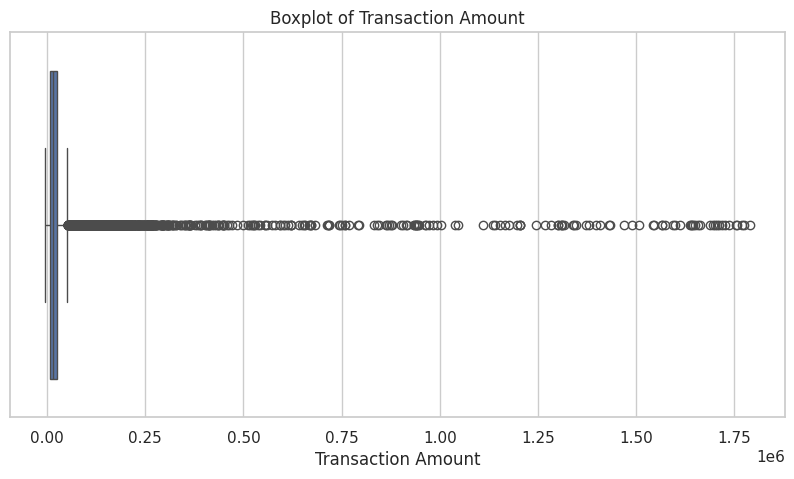

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Transaction_Amount"])

plt.title("Boxplot of Transaction Amount")
plt.xlabel("Transaction Amount")

plt.show()

**Method 2 – IQR Method**



The Interquartile Range (IQR) method is used to statistically identify potential outliers in transaction amounts.

The first quartile (Q1) represents the 25th percentile and the third quartile (Q3) represents the 75th percentile. The IQR is calculated as the difference between Q3 and Q1.

The lower and upper bounds are then calculated using 1.5 times the IQR. Transactions outside these limits are identified as potential outliers.

** Calculate Q1, Q3 and IQR**

In [31]:
Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

print(f"Q1  = {Q1:.2f}")
print(f"Q3  = {Q3:.2f}")
print(f"IQR = {IQR:.2f}")

Q1  = 7991.63
Q3  = 25516.86
IQR = 17525.23


Calculate Lower and Upper Bounds

In [32]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print(f"Lower Bound = {lower_bound:.2f}")
print(f"Upper Bound = {upper_bound:.2f}")

Lower Bound = -18296.22
Upper Bound = 51804.70


**Identify Transactions Outside the Limits**

In [33]:
outliers = df[
    (df["Transaction_Amount"] < lower_bound) |
    (df["Transaction_Amount"] > upper_bound)
]

print(f"Number of potential outlier transactions: {len(outliers)}")

Number of potential outlier transactions: 1238


**Display the Outlier Transactions**

In [34]:
outliers[
    ["Transaction_ID", "Customer_ID", "Transaction_Amount", "Transaction_Type"]
].head(20)

,Transaction_ID,Customer_ID,Transaction_Amount,Transaction_Type
1,TXN000002,CUST01935,80057.08,Online
6,TXN000007,CUST00215,276648.97,Online
8,TXN000009,CUST00504,290207.48,Online
17,TXN000018,CUST00321,179124.47,POS
20,TXN000021,CUST01251,110207.72,Online
43,TXN000044,CUST00887,83172.41,ATM
54,TXN000055,CUST01245,110801.50,POS
60,TXN000061,CUST02307,252092.67,POS
62,TXN000063,CUST00917,222218.72,ATM
69,TXN000070,CUST01174,181640.98,POS


**1. How many outliers are present?**


ANS: Using the IQR method, the calculated upper bound is 51,804.70 and the lower bound is -18,296.22. There are 1,238 potential outlier transactions outside these statistical limits.

**2. Which transactions are outliers?**


ANS: Transactions with a Transaction_Amount below -18,296.22 or above 51,804.70 are identified as potential outliers. Since transaction amounts are generally expected to be positive, the identified outliers are mainly transactions with unusually high transaction amounts above 51,804.70.

The records shown in the analysis include indices such as 1, 6, 17, 20, 43, 54, 60, 62, 69, 70, 71, 77, 78, 79, 86, 90, 108, and 136.

**3. Are all outliers fraudulent?**


ANS: No. An outlier is identified only because its transaction amount is statistically unusual compared with the majority of transactions. A high-value transaction can still be a genuine and legitimate banking transaction. Therefore, being an outlier does not automatically mean that the transaction is fraudulent.

**4. Should an outlier automatically be considered fraud?**


ANS: No. An outlier should be treated as a potentially unusual transaction requiring further investigation, rather than automatically being classified as fraud. Other factors such as transaction type, device type, location change, transaction timing, failed transactions, and the actual Is_Fraud status should be considered before determining whether the transaction is suspicious.

# **Important Business Question**

**Is an outlier necessarily an error?**

Answer: No. An outlier is not necessarily an error. It simply means that the transaction is unusually different from most other transactions. For example, a ₹10,00,000 transaction may be an extreme value, but it could still be a legitimate high-value transaction.

Therefore, extreme transactions should not be removed automatically. They should first be investigated using other transaction characteristics and business context before deciding whether they are errors or potentially fraudulent.

#**7. NumPy Analysis(PHASE 5)**

NumPy is used to perform numerical analysis on the transaction amounts. This helps us understand the central tendency, variability, and range of transaction values in the dataset.

The following measures will be calculated:
- Mean transaction amount
- Median transaction amount
- Standard deviation
- Minimum transaction amount
- Maximum transaction amount
- Percentiles

 **Convert Transaction_Amount to a NumPy array
 Drop missing values before performing numerical calculations**

In [35]:

transaction_amounts = df["Transaction_Amount"].dropna().to_numpy()

print("Number of transaction amounts analyzed:", len(transaction_amounts))

Number of transaction amounts analyzed: 10000


**Calculate mean transaction amount**

In [36]:
mean_amount = np.mean(transaction_amounts)

print(f"Mean Transaction Amount: {mean_amount:.2f}")

Mean Transaction Amount: 42556.68


**Calculate median transaction amount**

In [37]:

median_amount = np.median(transaction_amounts)

print(f"Median Transaction Amount: {median_amount:.2f}")

Median Transaction Amount: 14284.74


**Calculate standard deviation of transaction amounts**

In [38]:

std_amount = np.std(transaction_amounts)

print(f"Standard Deviation: {std_amount:.2f}")

Standard Deviation: 136511.29


** Calculate minimum transaction amount**

In [39]:
min_amount = np.min(transaction_amounts)

print(f"Minimum Transaction Amount: {min_amount:.2f}")

Minimum Transaction Amount: -4862.60


**Calculate maximum transaction amount**

In [40]:

max_amount = np.max(transaction_amounts)

print(f"Maximum Transaction Amount: {max_amount:.2f}")

Maximum Transaction Amount: 1789817.42


**Calculate important percentiles**

In [41]:
percentiles = np.percentile(
    transaction_amounts,
    [25, 50, 75, 90, 95, 99]
)

print("Transaction Amount Percentiles:")

for percentile, value in zip([25, 50, 75, 90, 95, 99], percentiles):
    print(f"{percentile}th Percentile: {value:.2f}")

Transaction Amount Percentiles:
25th Percentile: 7991.63
50th Percentile: 14284.74
75th Percentile: 25516.86
90th Percentile: 74673.74
95th Percentile: 152060.20
99th Percentile: 672890.68


**Fraudulent vs Non-Fraudulent Transactions**



To understand whether transaction amounts differ between fraudulent and non-fraudulent transactions, the mean, median, and standard deviation of transaction amounts are calculated separately for each fraud category.

In [42]:
fraudulent_amounts = df.loc[
    df["Is_Fraud"] == 1, "Transaction_Amount"
].dropna().to_numpy()

non_fraudulent_amounts = df.loc[
    df["Is_Fraud"] == 0, "Transaction_Amount"
].dropna().to_numpy()

print("Fraudulent transactions:", len(fraudulent_amounts))
print("Non-fraudulent transactions:", len(non_fraudulent_amounts))

Fraudulent transactions: 1314
Non-fraudulent transactions: 8686


**Calculate mean, median and standard deviation
for fraudulent and non-fraudulent transactions**

In [43]:
print("Fraudulent Transactions")
print(f"Mean     : {np.mean(fraudulent_amounts):.2f}")
print(f"Median   : {np.median(fraudulent_amounts):.2f}")
print(f"Std Dev  : {np.std(fraudulent_amounts):.2f}")

print("\nNon-Fraudulent Transactions")
print(f"Mean     : {np.mean(non_fraudulent_amounts):.2f}")
print(f"Median   : {np.median(non_fraudulent_amounts):.2f}")
print(f"Std Dev  : {np.std(non_fraudulent_amounts):.2f}")

Fraudulent Transactions
Mean     : 73647.41
Median   : 19183.15
Std Dev  : 191982.54

Non-Fraudulent Transactions
Mean     : 37853.33
Median   : 13802.49
Std Dev  : 125341.13


**Create a comparison table**

In [44]:
fraud_comparison = pd.DataFrame({
    "Metric": ["Mean", "Median", "Standard Deviation"],
    "Fraudulent": [
        np.mean(fraudulent_amounts),
        np.median(fraudulent_amounts),
        np.std(fraudulent_amounts)
    ],
    "Non-Fraudulent": [
        np.mean(non_fraudulent_amounts),
        np.median(non_fraudulent_amounts),
        np.std(non_fraudulent_amounts)
    ]
})

fraud_comparison.round(2)

,Metric,Fraudulent,Non-Fraudulent
0,Mean,73647.41,37853.33
1,Median,19183.16,13802.48
2,Standard Deviation,191982.54,125341.13


In [45]:
fraud_mean = np.mean(fraudulent_amounts)
non_fraud_mean = np.mean(non_fraudulent_amounts)

print(f"Mean transaction amount - Fraudulent     : {fraud_mean:.2f}")
print(f"Mean transaction amount - Non-Fraudulent : {non_fraud_mean:.2f}")

Mean transaction amount - Fraudulent     : 73647.41
Mean transaction amount - Non-Fraudulent : 37853.33


**Question: Is the average transaction amount higher for fraudulent transactions? Support your answer with calculations.**

Answer: Yes. The average transaction amount for fraudulent transactions is ₹73,647.41, while for non-fraudulent transactions it is ₹37,853.33.

Calculation:

₹73,647.41 − ₹37,853.33 = ₹35,794.08

Therefore, the average transaction amount for fraudulent transactions is ₹35,794.08 higher than for non-fraudulent transactions, indicating that fraudulent transactions in this dataset tend to have higher average transaction amounts.

# **8.EXPLORATORY DATA ANALYSIS(PHASE: 6-12)**
#**PHASE 6 – FRAUD DISTRIBUTION ANALYSIS**

The `Is_Fraud` variable represents whether a transaction is fraudulent or legitimate. This analysis determines the number of fraudulent and non-fraudulent transactions and calculates the overall fraud percentage.

A visualization is also created to clearly compare the distribution of fraudulent and non-fraudulent transactions.

**Count fraudulent transactions**

In [46]:
fraudulent_count = (df["Is_Fraud"] == 1).sum()

print(f"Number of fraudulent transactions: {fraudulent_count}")

Number of fraudulent transactions: 1314


**Count legitimate transactions**

In [47]:
legitimate_count = (df["Is_Fraud"] == 0).sum()

print(f"Number of legitimate transactions: {legitimate_count}")

Number of legitimate transactions: 8686


**Calculate fraud percentage**

In [48]:

total_transactions = len(df)

fraud_percentage = (fraudulent_count / total_transactions) * 100

print(f"Fraud percentage: {fraud_percentage:.2f}%")

Fraud percentage: 13.14%


### Fraud vs Non-Fraud Visualization

A bar chart is used to compare fraudulent and legitimate transactions. This makes the distribution of the target variable easy to understand and highlights the proportion of transactions associated with fraud.

**Create fraud vs non-fraud counts**

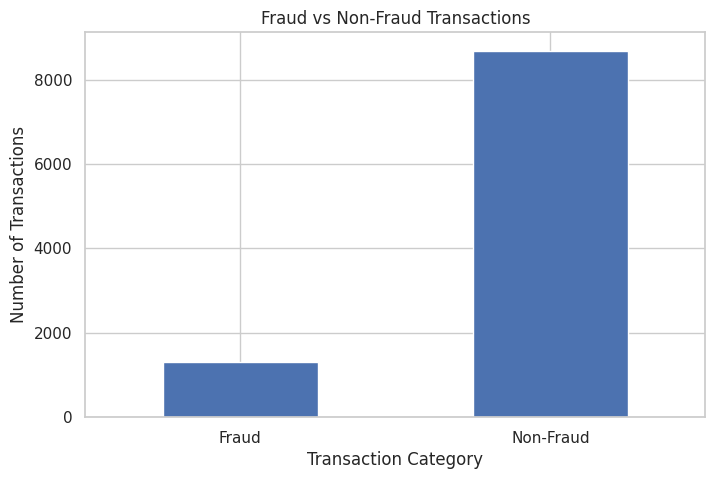

In [49]:
fraud_distribution = pd.Series({
    "Fraud": fraudulent_count,
    "Non-Fraud": legitimate_count
})

# Create bar chart

plt.figure(figsize=(8, 5))

fraud_distribution.plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

**1. Is the dataset balanced or imbalanced?**


Answer: The dataset is imbalanced. There are 1,314 fraudulent transactions (13.14%) compared with 8,686 legitimate transactions (86.86%), so legitimate transactions form the clear majority.

**2. Why could class imbalance become a problem in a real fraud detection system?**


Answer: Class imbalance can cause a model to favor the majority legitimate class and perform poorly at detecting the minority fraud class. In a real banking system, failing to detect fraudulent transactions can lead to financial losses and increased fraud risk.

#**PHASE 7 – FRAUD BY TRANSACTION TYPE**

We will analyze whether fraud is distributed differently across the three transaction types specified in the assignment:

Online

ATM

POS



Transaction type can provide useful insight into where fraudulent activity occurs. In this phase, we analyze fraudulent transactions across Online, ATM, and POS transaction types.

The fraud count for each transaction type will be calculated and visualized to compare the distribution of fraudulent transactions across these channels.

**Calculate the number of fraudulent transactions by transaction type**

In [50]:

fraud_by_type = df[df["Is_Fraud"] == 1]["Transaction_Type"].value_counts()

print("Fraudulent Transactions by Transaction Type:")
print(fraud_by_type)

Fraudulent Transactions by Transaction Type:
Transaction_Type
Online    828
POS       247
ATM       239
Name: count, dtype: int64


**Create Visualization**



A **bar chart** is used because it provides a clear comparison of the number of fraudulent transactions across Online, ATM, and POS transaction types.

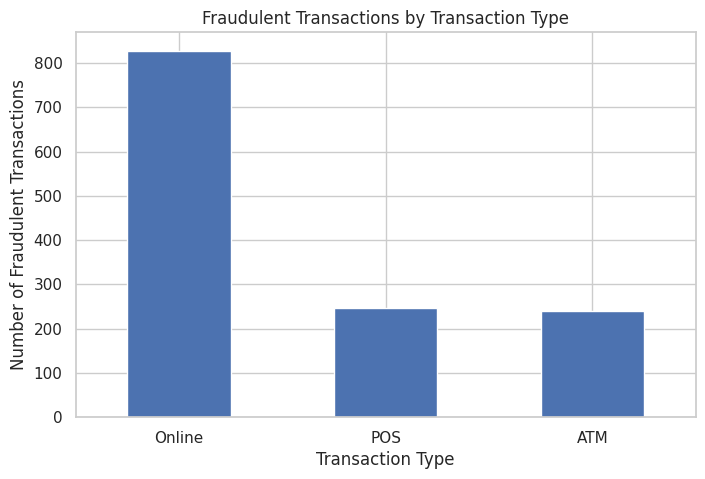

In [51]:


plt.figure(figsize=(8, 5))

fraud_by_type.plot(kind="bar")

plt.title("Fraudulent Transactions by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(rotation=0)

plt.show()

**1. Which transaction type has the highest number of fraud cases?**

Answer:
Online transactions have the highest number of fraud cases, with 828 fraudulent transactions, followed by POS (247) and ATM (239).

**2. Which transaction type has the highest fraud rate?**

In [52]:
fraud_rate_by_type = (
    df.groupby("Transaction_Type")["Is_Fraud"]
    .agg(["sum", "count"])
)

fraud_rate_by_type["Fraud_Rate_%"] = (
    fraud_rate_by_type["sum"] / fraud_rate_by_type["count"] * 100
)

fraud_rate_by_type

,sum,count,Fraud_Rate_%
Transaction_Type,,,
ATM,239,2325,10.279570
Online,828,5173,16.006186
POS,247,2502,9.872102


**Online transactions have the highest fraud rate at 16.01%, followed by ATM at 10.28% and POS at 9.87%.**

**3. Is online banking more risky than ATM/POS?**

Answer:

Based on this dataset, Online transactions show higher fraud risk than ATM and POS transactions. The fraud rate for Online transactions is 16.01%, compared with 10.28% for ATM and 9.87% for POS. Therefore, Online transactions should receive greater attention in fraud monitoring.

#**PHASE 8 – DEVICE ANALYSIS**

**We will analyze fraud based on the four device types specified in the assignment:**

Mobile

Laptop

ATM

Card

**The goal is to determine how fraudulent transactions are distributed across different devices.**



The device used for a transaction can provide useful information about fraudulent activity. In this phase, fraudulent transactions are analyzed across Mobile, Laptop, ATM, and Card devices.

The number of fraudulent transactions for each device type will be calculated and visualized to identify which devices are associated with a higher number of fraud cases.

**Calculate fraudulent transactions by device type**

In [53]:
fraud_by_device = (
    df[df["Is_Fraud"] == 1]["Device_Type"]
    .value_counts()
)

print("Fraudulent Transactions by Device Type:")
print(fraud_by_device)

Fraudulent Transactions by Device Type:
Device_Type
Mobile    672
ATM       238
Laptop    223
Card      181
Name: count, dtype: int64


**Create Visualization**


A **bar chart** is used to compare the number of fraudulent transactions across Mobile, Laptop, ATM, and Card devices. This visualization makes it easier to identify which device types have the highest number of fraud cases.

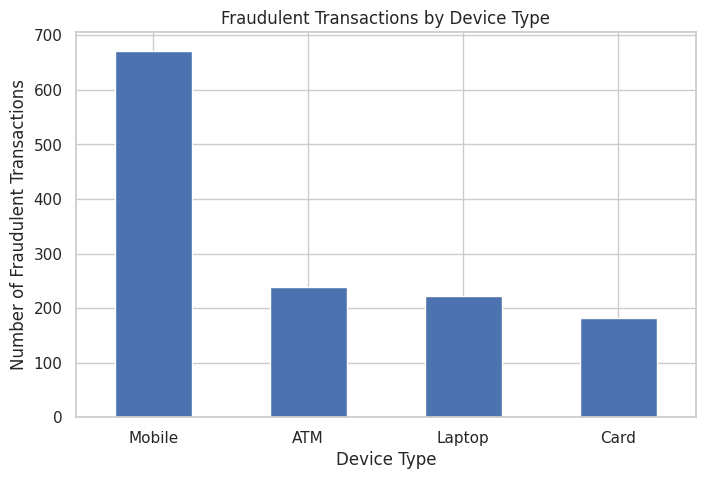

In [54]:


plt.figure(figsize=(8, 5))

fraud_by_device.plot(kind="bar")

plt.title("Fraudulent Transactions by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(rotation=0)

plt.show()

### Fraud Rate by Device Type

The number of fraud cases depends on how frequently each device is used. Therefore, fraud rate is also calculated for each device type to provide a fairer comparison.

Fraud Rate = Fraudulent Transactions / Total Transactions × 100

In [55]:
# Calculate fraud count, total transactions and fraud rate by device

device_analysis = (
    df.groupby("Device_Type")["Is_Fraud"]
    .agg(["sum", "count"])
)

device_analysis["Fraud_Rate_%"] = (
    device_analysis["sum"] / device_analysis["count"] * 100
)

device_analysis.columns = [
    "Fraudulent_Transactions",
    "Total_Transactions",
    "Fraud_Rate_%"
]

device_analysis.round(2)

,Fraudulent_Transactions,Total_Transactions,Fraud_Rate_%
Device_Type,,,
ATM,238,2327,10.23
Card,181,2001,9.05
Laptop,223,1701,13.11
Mobile,672,3971,16.92


**1. Which device is associated with the highest fraud?**

Answer:

Mobile devices are associated with the highest number of fraudulent transactions, with 672 fraud cases. This is considerably higher than ATM (238), Laptop (223), and Card (181).

**2. Does the device type appear to influence fraud?**

Answer:

Yes, the results suggest that device type is associated with different levels of fraud risk. Mobile has the highest fraud rate at 16.92%, while Card has the lowest at 9.05%. However, this shows an association in this dataset and does not by itself prove that device type directly causes fraud.

**3. What percentage of transactions from each device are fraudulent?**

he fraud percentage is calculated using:

Fraud Rate (%) = (Fraudulent Transactions ÷ Total Transactions) × 100

From data:

ATM: (238 ÷ 2327) × 100 = 10.23%

Card: (181 ÷ 2001) × 100 = 9.05%

Laptop: (223 ÷ 1701) × 100 = 13.11%

Mobile: (672 ÷ 3971) × 100 = 16.92%

So, Mobile has the highest fraud percentage: 16.92%.

# **PHASE 9 – LOCATION CHANGE ANALYSIS**



A change in transaction location may indicate unusual customer activity and can be an important factor in fraud analysis.

In this phase, transactions are compared based on whether the location changed or did not change, and their relationship with the fraud status is analyzed.

#Compare Location Change with Fraud

In [56]:
location_fraud = pd.crosstab(
    df["Location_Change"],
    df["Is_Fraud"]
)

location_fraud.columns = ["Non-Fraud", "Fraud"]

location_fraud

,Non-Fraud,Fraud
Location_Change,,
No,7120,728
Yes,1566,586


#Calculate Fraud Rate



Fraud count alone may be misleading because the number of transactions can differ between location-change categories. Therefore, the fraud rate is calculated for each category.

Fraud Rate (%) = (Fraudulent Transactions / Total Transactions) × 100

# Calculate fraud rate for each location-change category

In [57]:
location_analysis = (
    df.groupby("Location_Change")["Is_Fraud"]
    .agg(["sum", "count"])
)

location_analysis["Fraud_Rate_%"] = (
    location_analysis["sum"] /
    location_analysis["count"] * 100
)

location_analysis.columns = [
    "Fraudulent_Transactions",
    "Total_Transactions",
    "Fraud_Rate_%"
]

location_analysis.round(2)

,Fraudulent_Transactions,Total_Transactions,Fraud_Rate_%
Location_Change,,,
No,728,7848,9.28
Yes,586,2152,27.23


#Visualization


A bar chart is used to compare the fraud rates between transactions where the location changed and transactions where the location did not change. This provides a clear visual comparison of the relationship between location changes and fraudulent activity.

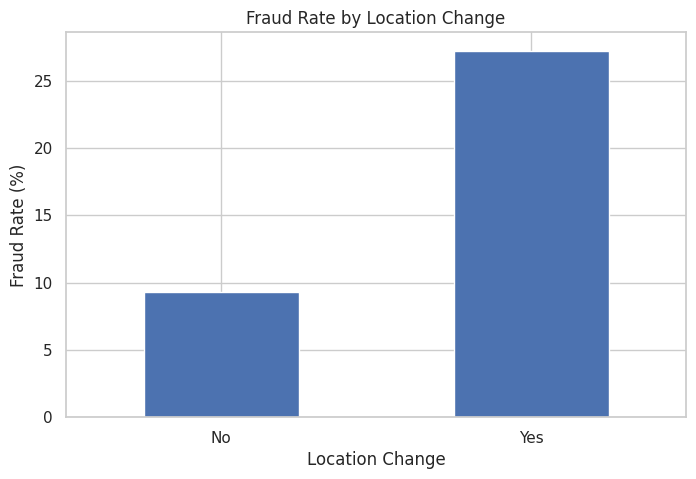

In [58]:


plt.figure(figsize=(8, 5))

location_analysis["Fraud_Rate_%"].plot(kind="bar")

plt.title("Fraud Rate by Location Change")
plt.xlabel("Location Change")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.show()

**Question. Are transactions involving a location change more likely to be fraudulent?**

Answer

Yes. Transactions involving a location change are more likely to be fraudulent in this dataset.

Location changed (Yes): 586 fraudulent out of 2,152 transactions → 27.23% fraud rate
Location did not change (No): 728 fraudulent out of 7,848 transactions → 9.28% fraud rate

Therefore, transactions with a location change have a much higher fraud rate (27.23%) compared with transactions without a location change (9.28%).

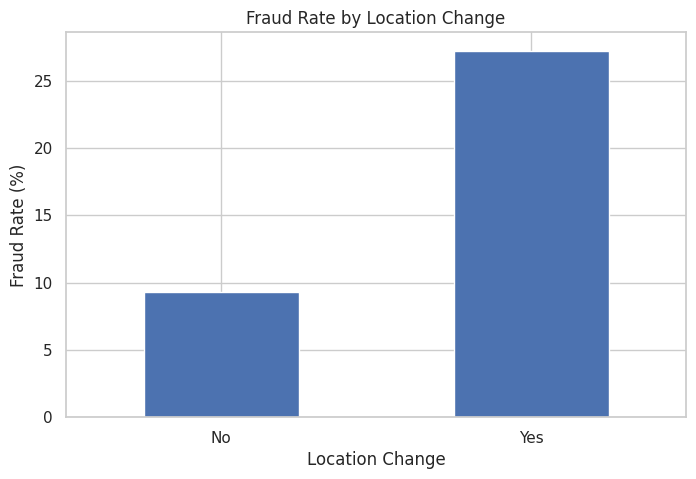

In [59]:
# Visualize fraud percentage by location change

plt.figure(figsize=(8, 5))

location_analysis["Fraud_Rate_%"].plot(kind="bar")

plt.title("Fraud Rate by Location Change")
plt.xlabel("Location Change")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.show()

# **PHASE 10 – TRANSACTION TIME ANALYSIS**



Transaction time can provide useful information about when fraudulent activity occurs.
In this phase, the transaction hour is grouped into meaningful time periods and fraud
is analyzed across these different periods.

The following categories are used:

- Morning: 5–11
- Afternoon: 12–16
- Evening: 17–20
- Night: 21–23
- Late Night: 0–4


#Create Time_Category

The `Transaction_Time_Hour` column contains the hour at which a transaction occurred.
To make the analysis easier to interpret, the hours are grouped into five time categories.

# Create Time_Category based on Transaction_Time_Hour

In [60]:
def categorize_time(hour):
    if 5 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    elif 17 <= hour <= 20:
        return "Evening"
    elif 21 <= hour <= 23:
        return "Night"
    elif 0 <= hour <= 4:
        return "Late Night"
    else:
        return np.nan

df["Time_Category"] = df["Transaction_Time_Hour"].apply(categorize_time)

df[["Transaction_Time_Hour", "Time_Category"]].head()

,Transaction_Time_Hour,Time_Category
0,10.0,Morning
1,17.0,Evening
2,4.0,Late Night
3,20.0,Evening
4,11.0,Morning


#Analyze Fraud Across Time Periods

### Fraud Analysis by Time Category

Fraudulent transactions are compared across the five time categories to identify
which periods have a higher number of fraudulent transactions.


# Count fraudulent transactions by time category

In [61]:
fraud_by_time = (
    df[df["Is_Fraud"] == 1]["Time_Category"]
    .value_counts()
)

print("Fraudulent Transactions by Time Category:")
print(fraud_by_time)

Fraudulent Transactions by Time Category:
Time_Category
Morning       439
Afternoon     281
Evening       254
Late Night    200
Night         139
Name: count, dtype: int64


#Calculate Fraud Rate for Each Time Period

### Fraud Rate by Time Category

Fraud count alone may not provide a fair comparison because different time periods
may contain different numbers of transactions. Therefore, the fraud rate is calculated
for each time category.

Fraud Rate (%) = (Fraudulent Transactions / Total Transactions) × 100


# Calculate fraud rate by time category

In [62]:
time_analysis = (
    df.groupby("Time_Category")["Is_Fraud"]
    .agg(["sum", "count"])
)

time_analysis["Fraud_Rate_%"] = (
    time_analysis["sum"] / time_analysis["count"] * 100
)

time_analysis.columns = [
    "Fraudulent_Transactions",
    "Total_Transactions",
    "Fraud_Rate_%"
]

time_analysis.round(2)

,Fraudulent_Transactions,Total_Transactions,Fraud_Rate_%
Time_Category,,,
Afternoon,281,2296,12.24
Evening,254,2211,11.49
Late Night,200,871,22.96
Morning,439,3395,12.93
Night,139,1211,11.48



#Visualization

### Fraud Rate Across Time Periods

A bar chart is used to compare fraud rates across Morning, Afternoon, Evening,
Night, and Late Night periods. This helps identify the time periods that show
higher levels of fraudulent activity.

# Visualize fraud rate by time category

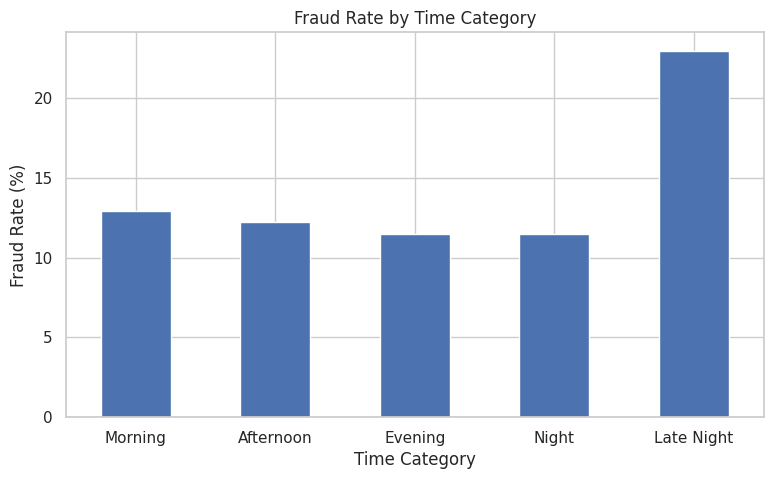

In [63]:
time_order = [
    "Morning",
    "Afternoon",
    "Evening",
    "Night",
    "Late Night"
]

time_analysis["Fraud_Rate_%"].reindex(time_order).plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Fraud Rate by Time Category")
plt.xlabel("Time Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.show()

**1. During which time period does fraud occur most frequently?**

ANS: Morning has the highest number of fraudulent transactions, with 439 fraudulent transactions.

However, this is the count, not the fraud rate. Morning also has the highest total transactions, so the higher fraud count is partly because there are more transactions during that period.

**2. Are late-night transactions more suspicious?**


ANS: Yes. Late Night is clearly more suspicious based on the fraud rate.

Late Night: 22.96% fraud rate
Morning: 12.93%
Afternoon: 12.24%
Evening: 11.49%
Night: 11.48%

So, late-night transactions have a much higher fraud rate than all other time categories.

**3. Is transaction time a useful fraud indicator?**


ANS: Yes. Transaction time appears to be a useful fraud indicator because fraud rates vary significantly across time categories.

The strongest finding is that Late Night transactions have a 22.96% fraud rate, almost twice the rate of the other periods. This suggests that transactions occurring during late-night hours deserve additional fraud monitoring.

# **Phase 11 – Failed Transactions Analysis**



### Objective
Analyze whether the number of failed transactions in the last 24 hours is associated with fraudulent transactions.

### Business Question
Do fraudulent transactions have more failed transactions in the last 24 hours compared to non-fraudulent transactions?

# Analyze Failed Transactions by Fraud Status

In [64]:
# Analyze Failed Transactions by Fraud Status

failed_analysis = df.groupby("Is_Fraud")["Failed_Transactions_Last_24h"].mean()

print("Average Failed Transactions by Fraud Status:")
print(failed_analysis)

Average Failed Transactions by Fraud Status:
Is_Fraud
0    0.828114
1    0.980213
Name: Failed_Transactions_Last_24h, dtype: float64


# Visualization: Failed Transactions vs Fraud Status

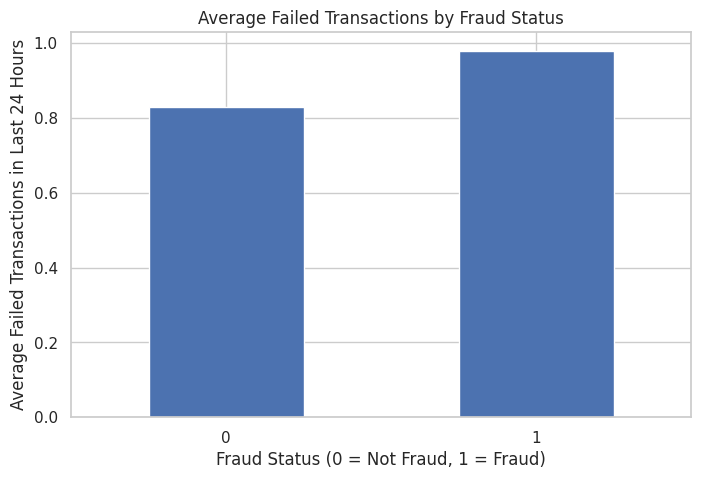

In [65]:
plt.figure(figsize=(8, 5))

failed_analysis.plot(kind="bar")

plt.title("Average Failed Transactions by Fraud Status")
plt.xlabel("Fraud Status (0 = Not Fraud, 1 = Fraud)")
plt.ylabel("Average Failed Transactions in Last 24 Hours")
plt.xticks(rotation=0)

plt.show()

# Display results with meaningful labels

In [66]:
failed_analysis_display = failed_analysis.rename(
    index={0: "Non-Fraudulent", 1: "Fraudulent"}
)

print("Average Failed Transactions:")
print(failed_analysis_display)

Average Failed Transactions:
Is_Fraud
Non-Fraudulent    0.828114
Fraudulent        0.980213
Name: Failed_Transactions_Last_24h, dtype: float64


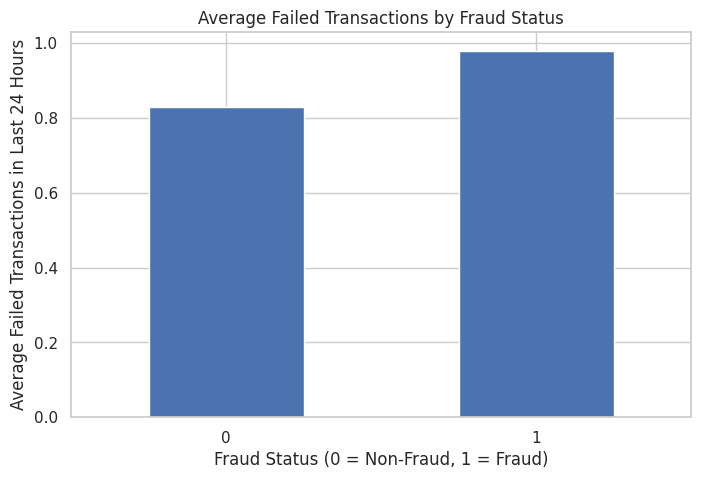

In [67]:
plt.figure(figsize=(8, 5))

failed_analysis.plot(kind="bar")

plt.title("Average Failed Transactions by Fraud Status")
plt.xlabel("Fraud Status (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Average Failed Transactions in Last 24 Hours")
plt.xticks(rotation=0)

plt.show()

**1. Do fraudulent transactions have more failed attempts?**

ANS: Yes. Fraudulent transactions have an average of 0.98 failed transactions, compared with 0.83 for non-fraudulent transactions. This shows that fraudulent transactions have slightly more failed attempts.

**2. What is the average number of failed transactions for fraud cases?**


ANS: The average number of failed transactions for fraudulent cases is 0.98 transactions in the last 24 hours.

**3. Does a higher number of failed transactions indicate increased risk?**


ANS: Yes, the results suggest that a higher number of failed transactions is associated with increased fraud risk. Fraudulent transactions have a higher average (0.98) than non-fraudulent transactions (0.83). However, the difference is relatively small, so this feature should be used along with other fraud indicators, rather than as a standalone indicator.

# **#Phase 12 – Correlation Analysis**



### Objective
Analyze the relationships between important numerical variables and fraud status using a correlation matrix.

### Variables Analyzed
- Transaction Amount
- Account Balance
- Age
- Transaction Time
- Failed Transactions
- Is_Fraud

#Select the Required Numerical Columns

In [68]:
correlation_data = df[
    [
        'Transaction_Amount',
        'Account_Balance',
        'Age',
        'Transaction_Time_Hour',
        'Failed_Transactions_Last_24h',
        'Is_Fraud'
    ]
]

correlation_data.head()

,Transaction_Amount,Account_Balance,Age,Transaction_Time_Hour,Failed_Transactions_Last_24h,Is_Fraud
0,20165.96,11695.06,51.0,10.0,0.0,0
1,80057.08,67506.61,27.0,17.0,0.0,0
2,11593.67,44740.16,37.0,4.0,1.0,1
3,11208.39,261985.75,54.0,20.0,0.0,0
4,12673.87,21390.58,54.0,11.0,0.0,0


#Create the Correlation Matrix

In [69]:
correlation_matrix = correlation_data.corr()

correlation_matrix

,Transaction_Amount,Account_Balance,Age,Transaction_Time_Hour,Failed_Transactions_Last_24h,Is_Fraud
Transaction_Amount,1.000000,0.034224,-0.003347,-0.018422,-0.014912,0.088583
Account_Balance,0.034224,1.000000,-0.012005,-0.008735,0.012665,-0.046086
Age,-0.003347,-0.012005,1.000000,0.015718,0.018123,0.000556
Transaction_Time_Hour,-0.018422,-0.008735,0.015718,1.000000,-0.012441,-0.064474
Failed_Transactions_Last_24h,-0.014912,0.012665,0.018123,-0.012441,1.000000,0.056737
Is_Fraud,0.088583,-0.046086,0.000556,-0.064474,0.056737,1.000000


#Visualize Using Seaborn Heatmap

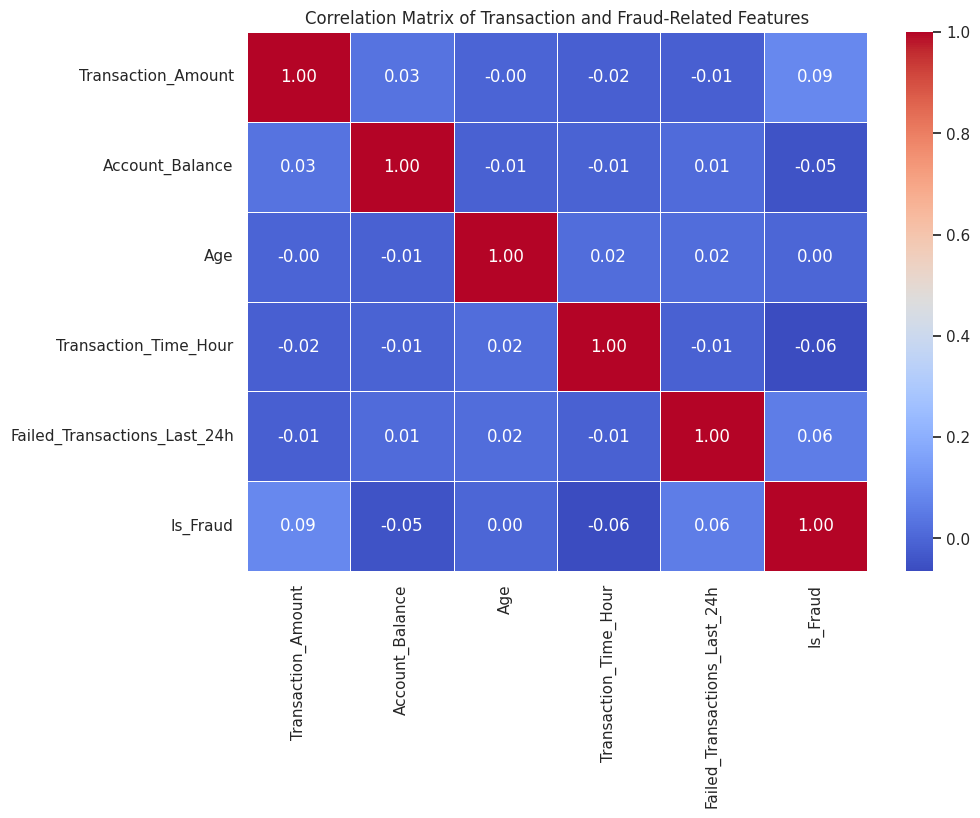

In [70]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Transaction and Fraud-Related Features')
plt.show()

**1. Which variables have the strongest relationship with fraud?**

ANS:
Among all the selected variables, Transaction Amount shows the strongest positive relationship with fraud, with a correlation value of 0.088583.

However, the correlation is very weak, since it is close to zero. The other variables also have very weak correlations with Is_Fraud. Therefore, based on the correlation matrix, none of the variables has a strong relationship with fraudulent transactions.

**2. Which variables appear unrelated?**

ANS:
Age appears to be almost completely unrelated to fraud because its correlation with Is_Fraud is only 0.000556, which is very close to zero.

The other variables also show very weak relationships with fraud:

Account Balance: -0.046086
Failed Transactions: 0.056737
Transaction Time Hour: -0.064474

Therefore, these variables do not show a meaningful linear relationship with Is_Fraud based on this correlation analysis.

**3. Are there highly correlated independent variables?**

ANS:
No, there are no highly correlated independent variables.

The highest correlation between the independent variables is between:

Transaction Amount and Account Balance = 0.034224

This value is very close to zero. The remaining independent variables also have correlations close to zero.

Therefore, the selected independent variables do not have significant multicollinearity. This means that the variables are not strongly linearly related to each other.

#9. Visualization Dashboard (PHASE 13)
Objective

To create a mini analytical dashboard using Matplotlib and Seaborn to visually analyze fraud patterns in the banking transaction dataset.

The dashboard will contain five visualizations:

Fraud vs Non-Fraud

Fraud by Transaction Type

Fraud by Device Type

Transaction Amount Distribution

Transaction Amount by Fraud Status

Visualization 6

Fraud by Time Category

Visualization 7

Fraud vs Location Change

Visualization 8

Correlation Heatmap

#Visualization 1 – Fraud vs Non-Fraud

This visualization shows the overall number of fraudulent and non-fraudulent transactions.

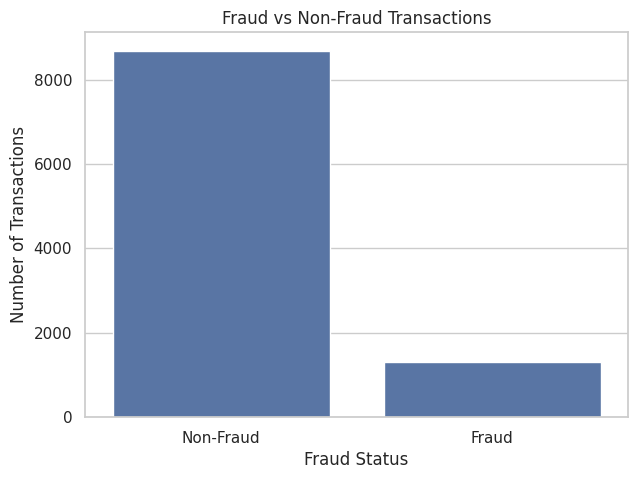

In [71]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Is_Fraud')

plt.title('Fraud vs Non-Fraud Transactions')
plt.xlabel('Fraud Status')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

#Visualization 2 – Fraud by Transaction Type Purpose

To identify which transaction types have more fraudulent transactions.

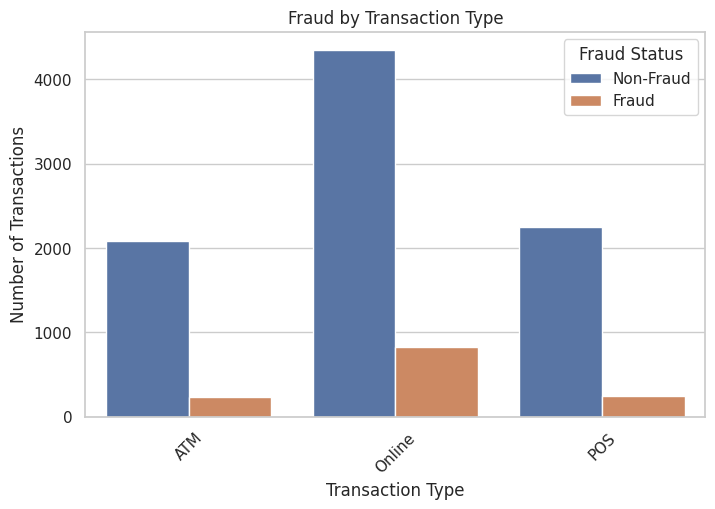

In [72]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Transaction_Type',
    hue='Is_Fraud'
)

plt.title('Fraud by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.legend(title='Fraud Status', labels=['Non-Fraud', 'Fraud'])

plt.xticks(rotation=45)
plt.show()

#Visualization 3 – Fraud by Device Type

Purpose

To analyze fraudulent transactions based on the device used for the transaction.

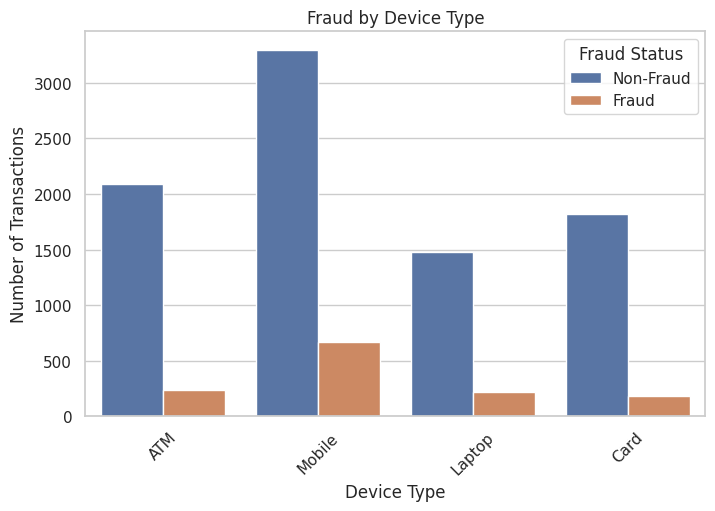

In [73]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Device_Type',
    hue='Is_Fraud'
)

plt.title('Fraud by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Number of Transactions')
plt.legend(title='Fraud Status', labels=['Non-Fraud', 'Fraud'])

plt.xticks(rotation=45)
plt.show()

#Visualization 4 – Transaction Amount Distribution Purpose

To understand the distribution of transaction amounts in the dataset.

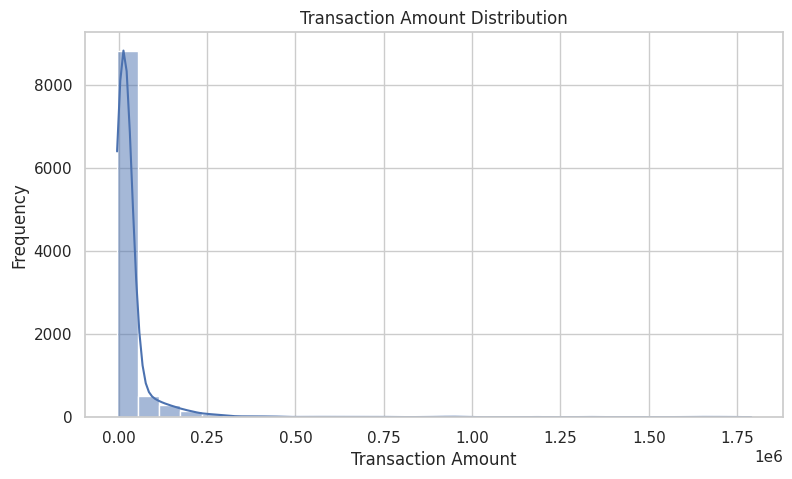

In [74]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Transaction_Amount',
    bins=30,
    kde=True
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

#Visualization 5 – Transaction Amount by Fraud Status

Purpose

To compare transaction amounts between fraudulent and non-fraudulent transactions.

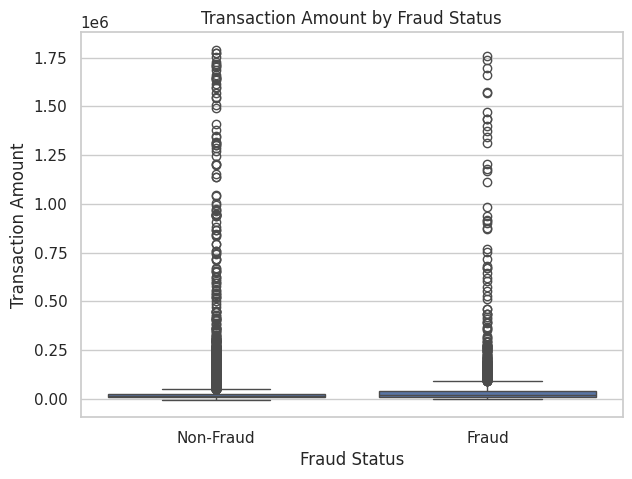

In [75]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Is_Fraud',
    y='Transaction_Amount'
)

plt.title('Transaction Amount by Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Transaction Amount')
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

#Visualization 6 – Fraud by Time Category

Purpose

To analyze whether fraudulent transactions are more common during particular time categories such as Morning, Afternoon, Evening, or Night.



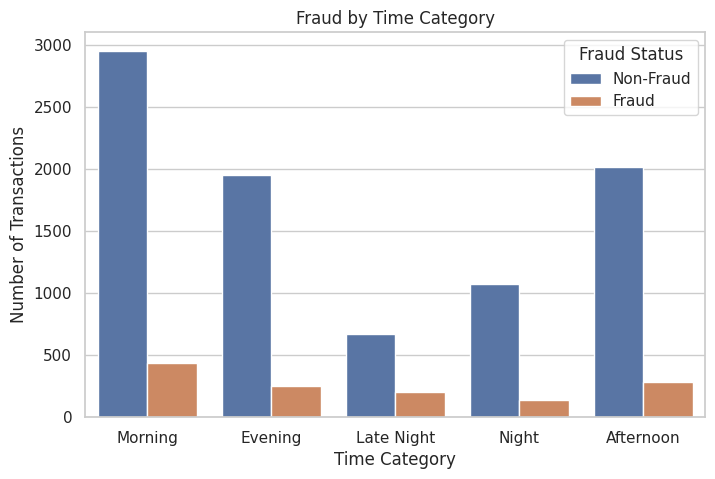

In [77]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Time_Category',
    hue='Is_Fraud'
)

plt.title('Fraud by Time Category')
plt.xlabel('Time Category')
plt.ylabel('Number of Transactions')
plt.legend(title='Fraud Status', labels=['Non-Fraud', 'Fraud'])

plt.show()

#Visualization 7 – Fraud vs Location Change Objective

To analyze whether a change in transaction location is associated with fraudulent activity.

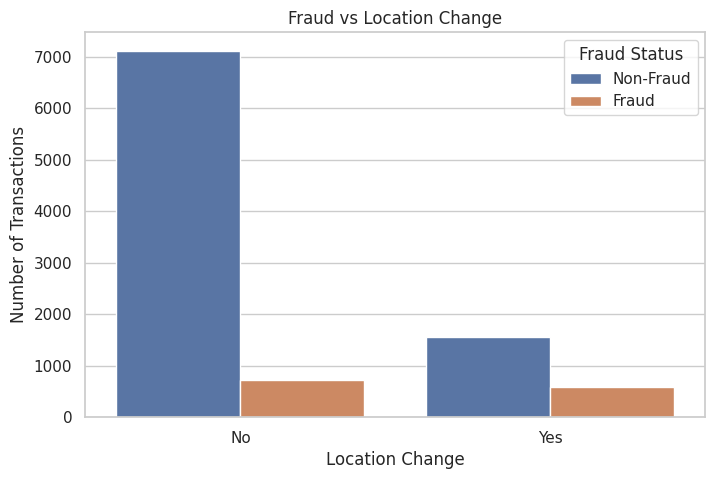

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Location_Change',
    hue='Is_Fraud'
)

plt.title('Fraud vs Location Change')
plt.xlabel('Location Change')
plt.ylabel('Number of Transactions')
plt.legend(title='Fraud Status', labels=['Non-Fraud', 'Fraud'])

plt.show()

#Visualization 8 – Correlation Heatmap

In [79]:
correlation_data = df[
    [
        'Transaction_Amount',
        'Account_Balance',
        'Age',
        'Transaction_Time_Hour',
        'Failed_Transactions_Last_24h',
        'Is_Fraud'
    ]
]

correlation_matrix = correlation_data.corr()

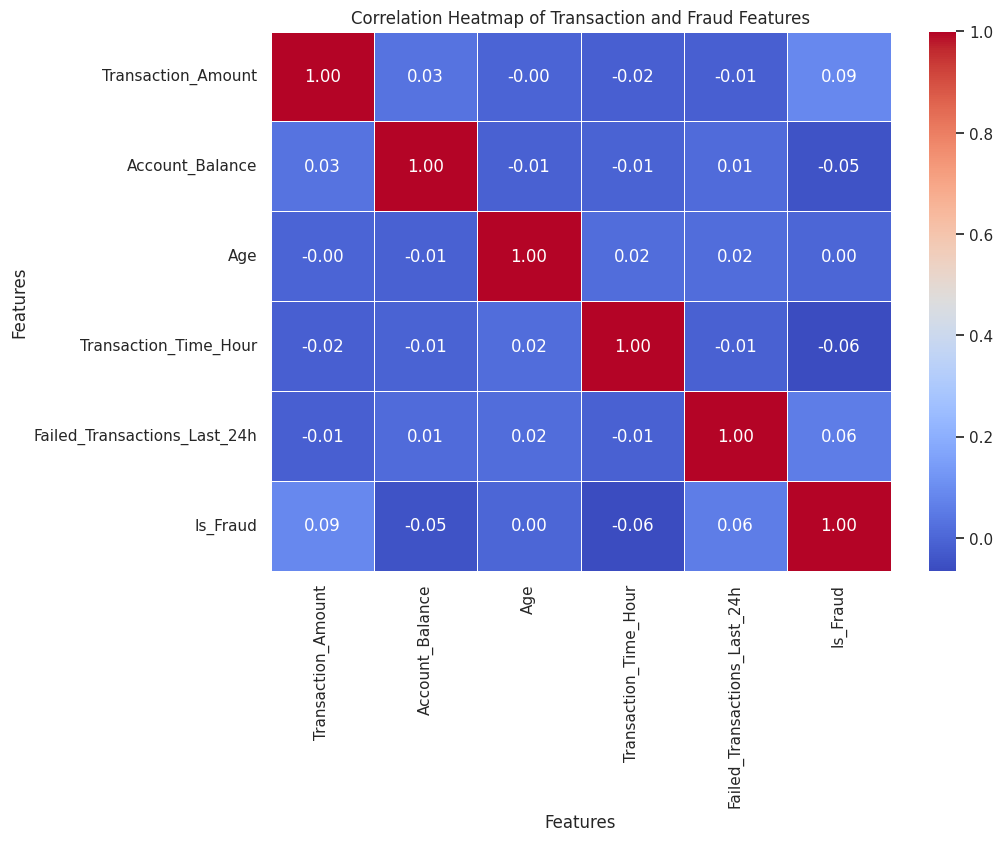

In [81]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Transaction and Fraud Features')
plt.xlabel('Features')
plt.ylabel('Features')

plt.show()

#**10. Feature Engineering (PHASE 14)**
Feature 1 – Transaction Ratio
**Objective**

Create a new feature called Transaction_Ratio to measure how large a transaction is compared with the customer's account balance.

Formula

Transaction_Ratio=
Account_Balance
/Transaction_Amount
	​


A higher transaction ratio means that the transaction represents a larger portion of the customer's available account balance.

In [82]:
df['Transaction_Ratio'] = (
    df['Transaction_Amount'] / df['Account_Balance']
)

In [83]:
df[['Transaction_Amount', 'Account_Balance', 'Transaction_Ratio']].head()

,Transaction_Amount,Account_Balance,Transaction_Ratio
0,20165.96,11695.06,1.724314
1,80057.08,67506.61,1.185915
2,11593.67,44740.16,0.259133
3,11208.39,261985.75,0.042782
4,12673.87,21390.58,0.592498


In [84]:
import numpy as np

print("Infinite values:", np.isinf(df['Transaction_Ratio']).sum())
print("Missing values:", df['Transaction_Ratio'].isnull().sum())

Infinite values: 0
Missing values: 0


In [85]:
df['Transaction_Ratio'] = np.where(
    df['Account_Balance'] > 0,
    df['Transaction_Amount'] / df['Account_Balance'],
    np.nan
)

#Feature 2 – High Value Transaction
 Objective
Create a new feature called Is_High_Value.

Rule:

Transaction_Amount > ₹1,00,000 → Yes
Otherwise → No

In [86]:


df['Is_High_Value'] = df['Transaction_Amount'].apply(
    lambda x: 'Yes' if x > 100000 else 'No'
)

df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0,Evening,0.042782,No
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0,Morning,0.592498,No


In [87]:


df['Is_High_Value'].value_counts()

,count
Is_High_Value,
No,9206
Yes,794


In [88]:
df['Is_High_Value'].value_counts(normalize=True) * 100

,proportion
Is_High_Value,
No,92.06
Yes,7.94


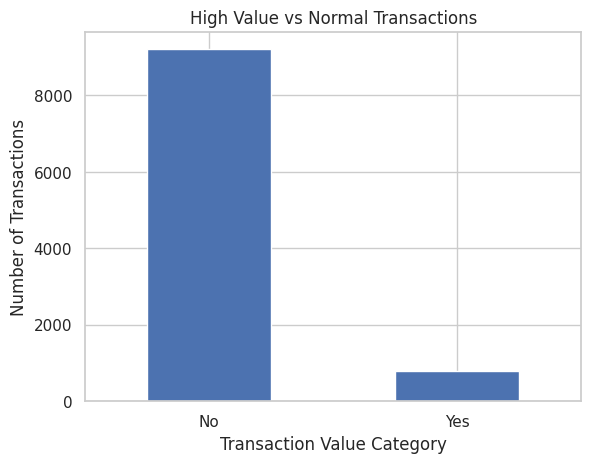

In [89]:
import matplotlib.pyplot as plt

df['Is_High_Value'].value_counts().plot(kind='bar')

plt.title('High Value vs Normal Transactions')
plt.xlabel('Transaction Value Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

#Feature 3 – High Risk Time
 Objective

Create a new feature called High_Risk_Time.

Rule:

Hour 0–4 → Yes
All other hours → No



In [92]:
# Feature 3: High Risk Time

df['High_Risk_Time'] = df['Transaction_Time_Hour'].apply(
    lambda x: 'Yes' if 0 <= x <= 4 else 'No'
)

df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value,High_Risk_Time
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No,No
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No,No
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No,Yes
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0,Evening,0.042782,No,No
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0,Morning,0.592498,No,No


In [93]:
df['High_Risk_Time'].value_counts()

,count
High_Risk_Time,
No,9129
Yes,871


In [94]:
df['High_Risk_Time'].value_counts(normalize=True) * 100

,proportion
High_Risk_Time,
No,91.29
Yes,8.71


In [95]:
pd.crosstab(
    df['High_Risk_Time'],
    df['Is_Fraud'],
    normalize='index'
) * 100

Is_Fraud,0,1
High_Risk_Time,,
No,87.797130,12.202870
Yes,77.037887,22.962113


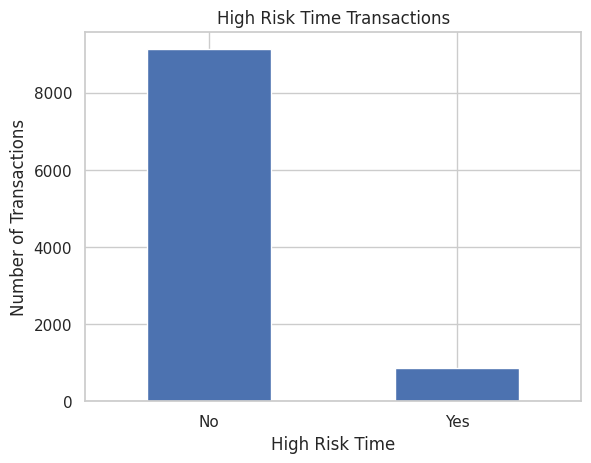

In [97]:
import matplotlib.pyplot as plt

df['High_Risk_Time'].value_counts().plot(kind='bar')

plt.title('High Risk Time Transactions')
plt.xlabel('High Risk Time')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

In [98]:
df['High_Risk_Time'] = df['Transaction_Time_Hour'].apply(
    lambda x: 'Yes' if 0 <= x <= 4 else 'No'
)

#Feature 4 – High Failed Attempts
 Objective

Create a new feature called High_Failed_Attempts.

Rule:

Failed Transactions >= 3 → Yes
Failed Transactions < 3 → No

In [100]:


df['High_Failed_Attempts'] = df['Failed_Transactions_Last_24h'].apply(
    lambda x: 'Yes' if x >= 3 else 'No'
)

df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value,High_Risk_Time,High_Failed_Attempts
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No,No,No
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No,No,No
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No,Yes,No
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0,Evening,0.042782,No,No,No
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0,Morning,0.592498,No,No,No


In [101]:
df['High_Failed_Attempts'].value_counts()

,count
High_Failed_Attempts,
No,9491
Yes,509


In [102]:
df['High_Failed_Attempts'].value_counts(normalize=True) * 100

,proportion
High_Failed_Attempts,
No,94.91
Yes,5.09


Check relationship with fraud

In [103]:
pd.crosstab(
    df['High_Failed_Attempts'],
    df['Is_Fraud'],
    normalize='index'
) * 100

Is_Fraud,0,1
High_Failed_Attempts,,
No,87.661996,12.338004
Yes,71.905697,28.094303


Visualization

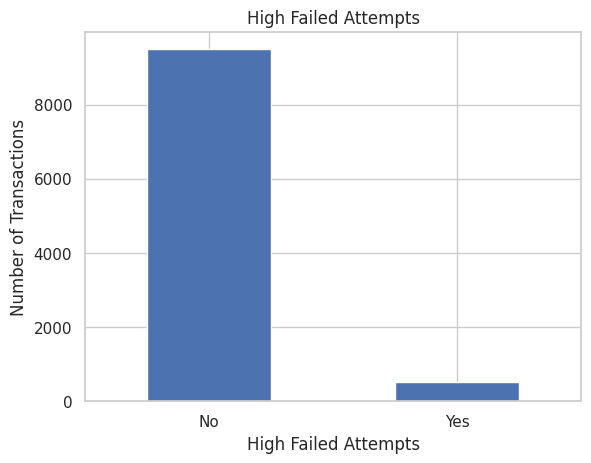

In [104]:
import matplotlib.pyplot as plt

df['High_Failed_Attempts'].value_counts().plot(kind='bar')

plt.title('High Failed Attempts')
plt.xlabel('High Failed Attempts')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

In [105]:
df['High_Failed_Attempts'] = df['Failed_Transactions_Last_24h'].apply(
    lambda x: 'Yes' if x >= 3 else 'No'
)

#**11.Identify Suspicious Transactions(PHASE 15)**
**Objective**

Create a new column:

Potentially_Suspicious

A transaction will be flagged Yes if at least one of these conditions is satisfied:

Very high transaction amount
Location changed
Transaction occurred during late night
Multiple failed transactions
Transaction amount is unusually high compared with account balance


Step 1 – Define the suspicious conditions

Based on the features you already created:

Is_High_Value == 'Yes'
Location_Change == 'Yes'
High_Risk_Time == 'Yes'
High_Failed_Attempts == 'Yes'
Transaction_Ratio is unusually high

For the last condition, we need a threshold. A simple rule is:

Transaction amount > 50% of account balance

So:

Transaction_Ratio > 0.5

#Identify Potentially Suspicious Transactions

In [106]:
df['Potentially_Suspicious'] = (
    (df['Is_High_Value'] == 'Yes') |
    (df['Location_Change'] == 'Yes') |
    (df['High_Risk_Time'] == 'Yes') |
    (df['High_Failed_Attempts'] == 'Yes') |
    (df['Transaction_Ratio'] > 0.5)
).map({True: 'Yes', False: 'No'})

df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value,High_Risk_Time,High_Failed_Attempts,Potentially_Suspicious
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No,No,No,Yes
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No,No,No,Yes
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No,Yes,No,Yes
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0,Evening,0.042782,No,No,No,No
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0,Morning,0.592498,No,No,No,Yes


Check how many transactions are suspicious

In [107]:
df['Potentially_Suspicious'].value_counts()

,count
Potentially_Suspicious,
Yes,5512
No,4488


**See the suspicious transactions**

In [108]:
suspicious_transactions = df[
    df['Potentially_Suspicious'] == 'Yes'
]

suspicious_transactions.head(10)

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value,High_Risk_Time,High_Failed_Attempts,Potentially_Suspicious
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No,No,No,Yes
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No,No,No,Yes
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No,Yes,No,Yes
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0,Morning,0.592498,No,No,No,Yes
5,TXN000006,CUST02147,22.0,Chennai,44335.95,Online,59945.82,Mobile,No,0.0,No,1.0,0,Late Night,0.739600,No,Yes,No,Yes
6,TXN000007,CUST00215,62.0,Chennai,276648.97,Online,98553.66,Mobile,No,21.0,No,0.0,1,Night,2.807090,Yes,No,No,Yes
8,TXN000009,CUST00504,24.0,Pune,290207.48,Online,28643.11,Mobile,No,7.0,No,1.0,0,Morning,10.131843,Yes,No,No,Yes
15,TXN000016,CUST01966,62.0,Vijayawada,15711.60,Online,72826.87,Laptop,Yes,16.0,No,0.0,0,Afternoon,0.215739,No,No,No,Yes
16,TXN000017,CUST01284,60.0,Vijayawada,13308.34,POS,124366.34,Card,No,0.0,Yes,1.0,0,Late Night,0.107009,No,Yes,No,Yes
17,TXN000018,CUST00321,69.0,Mumbai,179124.47,POS,166659.69,Card,No,17.0,Yes,0.0,0,Evening,1.074792,Yes,No,No,Yes


**Check the relationship with actual fraud**


In [109]:
pd.crosstab(
    df['Potentially_Suspicious'],
    df['Is_Fraud'],
    normalize='index'
) * 100

Is_Fraud,0,1
Potentially_Suspicious,,
No,94.897504,5.102496
Yes,80.315675,19.684325


**Count suspicious transactions by fraud status**

In [110]:
pd.crosstab(
    df['Potentially_Suspicious'],
    df['Is_Fraud']
)

Is_Fraud,0,1
Potentially_Suspicious,,
No,4259,229
Yes,4427,1085


**Find which rule is triggering the most**

In [111]:
suspicious_reasons = pd.DataFrame({
    'Very_High_Amount': df['Is_High_Value'] == 'Yes',
    'Location_Changed': df['Location_Change'] == 'Yes',
    'Late_Night': df['High_Risk_Time'] == 'Yes',
    'Multiple_Failed_Transactions': df['High_Failed_Attempts'] == 'Yes',
    'High_Transaction_Ratio': df['Transaction_Ratio'] > 0.5
})

suspicious_reasons.sum().sort_values(ascending=False)

,0
High_Transaction_Ratio,3357
Location_Changed,2152
Late_Night,871
Very_High_Amount,794
Multiple_Failed_Transactions,509


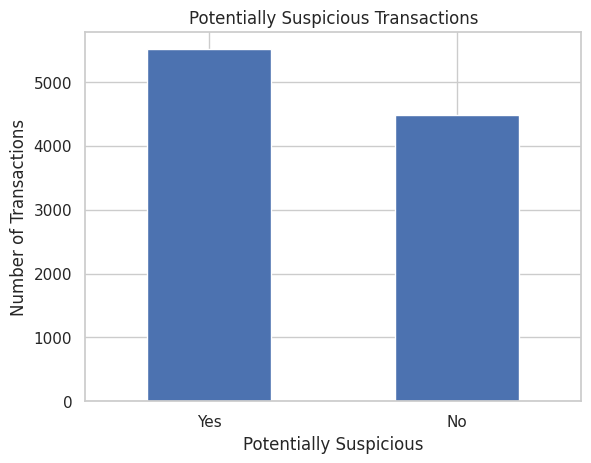

In [113]:
import matplotlib.pyplot as plt

df['Potentially_Suspicious'].value_counts().plot(kind='bar')

plt.title('Potentially Suspicious Transactions')
plt.xlabel('Potentially Suspicious')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

#FINAL BUSINESS QUESTIONS & ANSWERS


**Question 1: What are the strongest indicators of fraudulent transactions?**

Answer:
The main indicators are high transaction amount, location change, late-night transactions, and multiple failed transactions. Online transactions and mobile devices also show higher fraud rates. These indicators do not prove fraud individually but help identify transactions that need further investigation.


**Question 2: Are high-value transactions more likely to be fraudulent?**

Answer:
Yes. High-value transactions have a fraud rate of 28.21%, compared with 11.84% for normal transactions. This shows that high-value transactions have a higher fraud risk.

**Question 3: Does a location change indicate higher fraud risk?**

Answer:
Yes. Transactions with a location change have a fraud rate of 27.23%, while transactions without a location change have 9.28%. Therefore, location change is an important fraud-risk indicator.

**Question 4: Does transaction time influence fraud?**

Answer:
Yes. Late-night transactions between 12 AM and 4 AM have the highest fraud rate of 22.96%. This indicates that transaction timing can influence fraud risk.

**Question 5: Does the number of failed transactions correlate with fraud?**

Answer:
Yes, but weakly. Fraudulent transactions have slightly more failed attempts on average. Transactions with 3 or more failed attempts show higher fraud risk. Therefore, failed attempts are a supporting indicator rather than proof of fraud.

**Question 6: Which transaction type has the highest fraud rate?**

Answer:
Online transactions have the highest fraud rate at 16.01%. ATM transactions have 10.28%, while POS transactions have 9.87%.

**Question 7: Which device type has the highest fraud rate?**

Answer:
Mobile devices have the highest fraud rate at 16.92%, followed by Laptop (13.11%), ATM (10.23%), and Card (9.05%).

**Question 8: Are outliers necessarily fraudulent?**

Answer:
No. An outlier is simply an unusually large or unusual transaction. It does not automatically mean fraud. Outliers can be legitimate transactions, but they may deserve further investigation when combined with other risk indicators.

**Question 9: Which variables should the bank monitor more closely?**

Answer:
The bank should closely monitor:

Transaction Amount – especially high-value transactions.
Location Change – shows a higher fraud rate.
Transaction Time – especially transactions between 12 AM and 4 AM.
Failed Transactions – particularly 3 or more failed attempts.
Transaction Type – especially Online transactions.
Device Type – especially Mobile transactions.
Transaction Ratio – unusually high transaction amount compared with account balance.

These variables can help the bank identify transactions that require further investigation.


**Question 10: What recommendations would you give to the bank?**

Answer:

**Monitor high-value transactions:**
The bank should closely monitor transactions above ₹1,00,000, as these transactions showed a higher fraud rate in the analysis.

**Monitor location changes:**
Transactions involving a sudden location change should receive additional attention, especially when combined with other suspicious activities.


**Increase late-night monitoring:**
Transactions occurring between 12 AM and 4 AM should be monitored more closely because this time period showed a higher fraud rate.


**Track multiple failed transactions:**
Customers with 3 or more failed transactions should be flagged for additional verification, as repeated failures may indicate suspicious activity.

**Strengthen online and mobile security:**
Since Online transactions and Mobile devices showed higher fraud rates, the bank should apply stronger authentication and monitoring to these transactions.


**Use multiple indicators together:**
The bank should not depend on one factor alone. For example, a high-value transaction combined with a location change and late-night activity would deserve greater attention.


**Investigate suspicious transactions:**
Transactions flagged as potentially suspicious should be reviewed or verified before being considered fraudulent. The purpose of the system should be to identify transactions for investigation, not automatically label them as fraud.

**Do not automatically classify outliers as fraud:**
An unusually large transaction may be legitimate. Therefore, outliers should be treated as warning signals and investigated using other transaction information.



#**12. KEY INSIGHTS**




**Finding 1** – High-Value Transactions

Transactions above ₹1,00,000 have a higher fraud rate. The bank should closely monitor unusually large transactions.

**Finding 2** – Location Changes

Transactions involving a location change show a significantly higher fraud rate. Sudden changes in transaction location should be treated as an important warning signal.

**Finding 3** – Late-Night Transactions

Transactions between 12 AM and 4 AM have the highest fraud rate among the time categories. These transactions should receive additional monitoring.

**Finding 4** – Multiple Failed Transactions

Transactions with 3 or more failed attempts show increased fraud risk. Repeated failed transactions should trigger additional verification.

**Finding 5** – Online and Mobile Transactions

Online transactions and mobile-device transactions have comparatively higher fraud rates. These channels should receive stronger monitoring and authentication.

#**13. Business Recommendations**



### Recommendation 1 – Implement Risk-Based Transaction Monitoring

The bank should implement a **multi-factor risk monitoring system** that evaluates transaction amount, location changes, transaction time, failed attempts, transaction type, and device type together. Transactions showing multiple risk indicators should be prioritized for investigation.

### Recommendation 2 – Strengthen Controls for High-Risk Transactions

Apply **additional authentication and verification** to high-value, late-night, location-changed, online, and mobile transactions. This can help prevent unauthorized transactions while minimizing unnecessary disruption to legitimate customers.

### Recommendation 3 – Enable Real-Time Fraud Alerts

Develop a **real-time alert mechanism** that immediately flags transactions meeting multiple suspicious conditions. Alerts should be routed to the fraud team for timely investigation, helping the bank reduce potential financial losses and respond faster to emerging fraud patterns.


#**14. Conclusion**


In this project, I analyzed the banking transaction dataset to understand the patterns associated with fraudulent transactions. Through data cleaning, exploratory data analysis, feature engineering, and visualization, I identified several important risk indicators.

My analysis shows that **high-value transactions, location changes, late-night transactions, multiple failed attempts, online transactions, and mobile-device transactionS** are associated with higher fraud risk.

 I also found that unusual transactions or outliers should not automatically be considered fraudulent, but they can be useful signals for further investigation.

Based on my analysis, I recommend that the bank use multiple risk indicators together rather than depending on a single factor. This can help the bank identify potentially suspicious transactions earlier and focus investigation efforts on the transactions that require the most attention.

**Overall, this analysis helped me convert transaction-level data into meaningful business insights that can support the bank in improving fraud monitoring, reducing potential losses, and strengthening customer protection.**